## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Andrew Nguyen

**Date:** 10-21-26

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:
Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

---
The histogram is heavily right skewed. Most tokens appear only a few times, while less occur very frequently, creating a tail. 

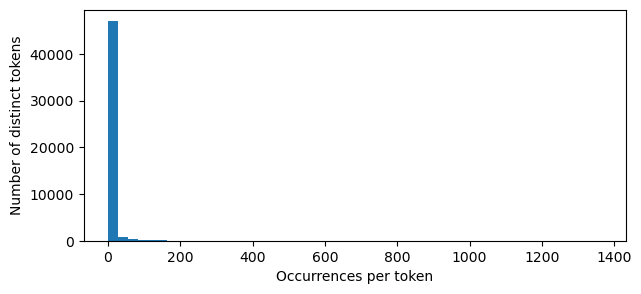

In [28]:
counts = list(token_count.values())

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 3))
plt.hist(counts, bins=50)
plt.xlabel("Occurrences per token")
plt.ylabel("Number of distinct tokens")
plt.show()

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

---
The $R^2$ on the test set was -7.57 x $10^23$, which indicated extremely poor generalization. The training $R^2$ value was 0.7663, so the model explained about 76.63% of the training outcome variation.

The largest absolute coefficients were "reserved," the image-URL token, "underline,", "iit," and "demokritos."  

In [29]:
import pandas as pd

emails = pd.read_parquet("data/Phishing_clean.parquet")

X = emails.drop(columns=["Email Type"])
y = emails["Email Type"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

from sklearn.linear_model import LinearRegression

fit = LinearRegression().fit(X_train, y_train)

print("Training R²:", fit.score(X_train, y_train))
print("Test R²:", fit.score(X_test, y_test))

coefficients = pd.Series(fit.coef_, index=X.columns)

largest = coefficients.abs().sort_values(ascending=False).head(10)
print(coefficients.loc[largest.index])

Training R²: 0.7662702774771087
Test R²: -7.57402933885971e+23
reserved.                                                        -2.377168e+13
url(http://images.lockergnome.com/images/issue/top-right.gif);   -1.485430e+13
underline;                                                        1.485430e+13
iit                                                               1.053085e+13
demokritos                                                       -1.053085e+13
400                                                               1.035349e+13
-0700                                                            -1.030949e+13
pudge.                                                            1.009209e+13
800                                                               1.000509e+13
1997                                                             -9.473526e+12
dtype: float64


In [30]:
print("Number of features:", X_train.shape[1])
print("Matrix rank:", fit.rank_)
print("Smallest singular values:", fit.singular_[-5:])
print("Test prediction range:",
      fit.predict(X_test).min(),
      fit.predict(X_test).max())

Number of features: 2711
Matrix rank: 2649
Smallest singular values: [2.19242285e-15 2.10843945e-15 2.03059502e-15 1.93429218e-15
 1.73267971e-15]
Test prediction range: -23771675583752.293 7004991924864.075


**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

---
I noticed that the scam and non scam emaiks overlap a lot, especially in the main cluster. However, the groups in the larger PC1 values are mostly non-scam, while scam emails tend to have higher PC2 values within the main cluster. These patterns are still very small, and I do not see them clearly separating the two email types.

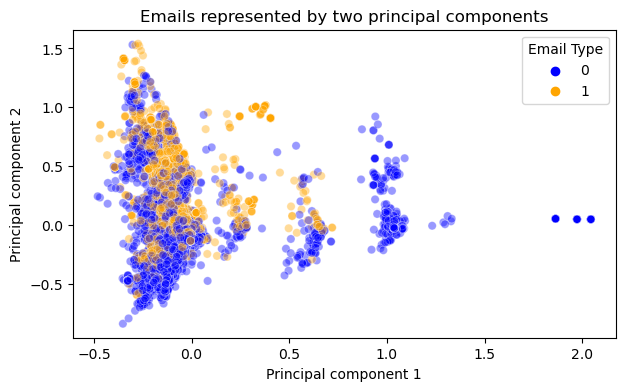

In [31]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
components = pca.fit_transform(X)

plt.figure(figsize=(7, 4))
sns.scatterplot(
    x=components[:, 0],
    y=components[:, 1],
    hue=y,
    palette={0: "blue", 1: "orange"}, #blue is non scam orange is scam
    alpha=0.4
)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("Emails represented by two principal components")
plt.show()

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

---
The R squared for training data was 0.7662, and the test R squared was 0.6683. The training performance was nearly identical to the original regressio, but the test performance improved by a lot.

In [32]:
pca_reg = PCA(n_components=2610)

X_train_pca = pca_reg.fit_transform(X_train)
X_test_pca = pca_reg.transform(X_test)

pca_fit = LinearRegression().fit(X_train_pca, y_train)

R2_train = pca_fit.score(X_train_pca, y_train)
R2_test = pca_fit.score(X_test_pca, y_test)

print("R squared for training data:", R2_train)
print("R squared for testing data:", R2_test)

R squared for training data: 0.7662326827745852
R squared for testing data: 0.6683390643101161


**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---
PCA combines overlapping information from many features into components. Keeping fewer components can remove redundant or unstable directions, and also can help us better understand the data. Removing the unstable directions can make the regression predictions more reliable on unseen data. 

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 33ac6f9171862ba7b71b9e38de42f1615ced5555
- **AI tool and model used:** GPT 6.1 sol light

### *Prompts used

1. Review my notebook.ipynb and the assignment rubric for Phase 2. Keep Phase 1 frozen and do not edit it.
Review Q1–Q5 for correctness, interpretation, numerical stability, and data leakage. I want you to particularly look at the extreme negative test R² and large coefficients in Q2, and whether the PCA comparison in Q4 is valid cuz idk if thats right.
First, give me a concise numbered list of proposed changes that I can paste verbatim into “AI-proposed changes.” For each change, explain why it helps and suggest a concrete way I can verify it. Distinguish necessary corrections from optional improvements.
Please do not make any changes to the notebook yet, ill evaluate each suggestion as accept, modifym or reject and then we can prepare the full phase 2. Try and preserve the assignments required linear regression models and component counts.

### *AI-proposed changes


1. Necessary — Correct Q2’s explanation of the extreme test R². Explain that the rank-deficient training matrix (reported rank 2,649 versus 2,711 features), near-zero singular values, coefficients around \(10^{13}\), and enormous test predictions indicate numerical instability alongside possible overfitting. The negative R² means predictions perform worse than predicting the test-set mean; it does not establish that ordinary linear regression is inherently unsuitable. Verify: rerun the diagnostics and inspect prediction magnitudes, residuals, and the centered matrix’s singular-value spectrum.
2. Necessary — Qualify Q2’s coefficient interpretation. Preserve the requested largest-absolute-coefficient list, but explain that these unstable coefficients cannot reliably identify the most influential words. Correlated or dependent features can have huge coefficients that cancel on training data. Verify: check whether the highlighted token columns are identical or highly correlated in training data, and compare coefficient rankings under a documented, numerically stable least-squares tolerance.
3. Necessary — Retain Q4’s required comparison but qualify its conclusion. The current comparison is structurally valid: both regressions use the same split, and Q4 fits PCA only on training data before transforming test data. Keep linear regression and exactly 2,610 components. Explain that PCA’s improvement over the unstable Q2 fit does not by itself prove superiority over a numerically stable regression on the original features. Verify: reproduce both reported R² values on the same split and add a clearly labeled stable least-squares diagnostic baseline without replacing either required model.
4. Necessary — Tighten Q5’s explanation. Explain that retaining fewer principal components removes low-variance directions and can improve conditioning, but does not guarantee improved prediction: discarded directions may contain outcome information. PCA maximizes feature variance, not phishing separation, and its components can be harder to interpret than individual tokens. Verify: report the retained explained-variance fraction and inspect the smallest retained singular values alongside the train/test results.
5. Optional — Clarify Q3’s exploratory scope and make PCA reproducible. Fitting two-component PCA on all features is acceptable for the assignment’s descriptive plot, but that fitted transformation should not inform predictive evaluation or model selection. Q4 already uses the correct training-only approach. Specify PCA’s solver and, when applicable, a random seed. Verify: confirm Email Type is excluded from PCA inputs, inspect the plotted class patterns, and report the two components’ explained-variance ratios.
6. Optional — Improve Q1’s visualization while retaining the original histogram. The right-skew interpretation is appropriate; add a log-scaled view or token-frequency summary to make the long tail easier to see. Verify: confirm every distinct token contributes one occurrence count to the histogram and compare the minimum, median, maximum, and most common token counts.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | `Accept` / modify / reject | I feel this is a good thing to incorporate, because I originally connected the extreme negative R squared value to poor generalization, but I never explained the numerical instability. |
| 2 | `Accept` / modify / reject | My coefficient list answers the question, but the huge unstable coefficients do not reliably identify influential words.   |
| 3 | Accept / `modify` / reject | My existing comparison uses the same split and already correctly fits PCA only on training data. Therefore, I can preserve both required models and 2610 components, but qualify the conclusion because the original regression is unstable.  |
| 4 | `Accept` / modify / reject | Even though my explanation is broadly correct, it should state that PCA can discard predictive information and does not guarantee better predictions. |
| 5 | Accept / modify / `reject` | Q3 is an exploratory visualization, and Q4 already uses training-only PCA. These optional additions are unnecessary for correcting my main answers. |
| 6 | Accept / `modify` / reject | My histogram already satisfies Q1, but maybe I can take a look at how to make it easier to interpret since the right skew is so extreme. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:
Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

---
The histogram is heavily right skewed. Most tokens appear only a few times, while less occur very frequently, creating a tail. 

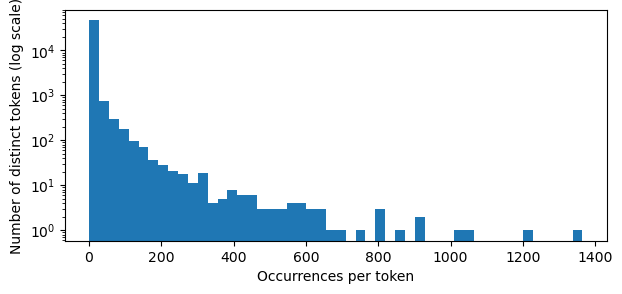

In [7]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

counts = list(token_count.values())

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 3))
plt.hist(counts, bins=50)
plt.xlabel("Occurrences per token")
plt.yscale("log")
plt.ylabel("Number of distinct tokens (log scale)")
plt.show()

The log scale makes the less common histogram bins easier to see. The distribution is still heavily right skewed.

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

---
The training and test $R^2$ values are printed below. In Phase 1, the test $R^2$ was about $-7.57 \times 10^{23}$, while training $R^2$ was 0.7663. The negative test value means the predictions were worse than using the test outcome mean. The very large coefficients, near-zero singular values, and huge test predictions suggest numerical instability, so poor generalization alone does not explain what happened.

The largest absolute coefficients are listed below. In Phase 1 these included "reserved.", the image-URL token, "underline;", "iit", and "demokritos". However, these unstable coefficients do not reliably tell us which words most strongly influence predictions. Dependent features can have very large coefficients that cancel on the training data.


In [8]:
import pandas as pd

emails = pd.read_parquet("data/Phishing_clean.parquet")

X = emails.drop(columns=["Email Type"])
y = emails["Email Type"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

from sklearn.linear_model import LinearRegression

fit = LinearRegression().fit(X_train, y_train)

print("Training R²:", fit.score(X_train, y_train))
print("Test R²:", fit.score(X_test, y_test))

coefficients = pd.Series(fit.coef_, index=X.columns)

largest = coefficients.abs().sort_values(ascending=False).head(10)
print(coefficients.loc[largest.index])

Training R²: 0.7662702774771087
Test R²: -7.57402933885971e+23
reserved.                                                        -2.377168e+13
url(http://images.lockergnome.com/images/issue/top-right.gif);   -1.485430e+13
underline;                                                        1.485430e+13
iit                                                               1.053085e+13
demokritos                                                       -1.053085e+13
400                                                               1.035349e+13
-0700                                                            -1.030949e+13
pudge.                                                            1.009209e+13
800                                                               1.000509e+13
1997                                                             -9.473526e+12
dtype: float64


In [9]:
print("Number of features:", X_train.shape[1])
print("Matrix rank:", fit.rank_)
print("Smallest singular values:", fit.singular_[-5:])
print("Test prediction range:",
      fit.predict(X_test).min(),
      fit.predict(X_test).max())

Number of features: 2711
Matrix rank: 2649
Smallest singular values: [2.19242285e-15 2.10843945e-15 2.03059502e-15 1.93429218e-15
 1.73267971e-15]
Test prediction range: -23771675583752.293 7004991924864.075


In [10]:
import numpy as np
from scipy.linalg import lstsq

predictions = fit.predict(X_test)
print("Largest absolute test residual:", np.abs(y_test - predictions).max())
print("Centered training matrix singular-value ratio:",
      fit.singular_[0] / fit.singular_[-1])

# Check relationships among the five largest-coefficient token columns.
top_words = largest.index[:5]
print("Training correlations among the highlighted tokens:")
print(X_train[top_words].corr().round(3))

# Diagnostic only: keep the required original regression above.
# Center using training means, and discard singular values below 1e-10
# times the largest singular value for this least-squares calculation.
X_mean = X_train.mean()
y_mean = y_train.mean()
stable_coef, _, stable_rank, _ = lstsq(
    X_train.to_numpy(dtype=float) - X_mean.to_numpy(),
    y_train.to_numpy(dtype=float) - y_mean,
    cond=1e-10
)
stable_coefficients = pd.Series(stable_coef, index=X.columns)
stable_largest = stable_coefficients.abs().sort_values(ascending=False).head(10)
print("Diagnostic rank with relative cutoff 1e-10:", stable_rank)
print("Largest coefficients with this cutoff:")
print(stable_coefficients.loc[stable_largest.index])
print("Overlap with original top ten:",
      len(set(largest.index) & set(stable_largest.index)))


Largest absolute test residual: 23771675583753.293
Centered training matrix singular-value ratio: 2.1510108054451864e+16
Training correlations among the highlighted tokens:
                                                    reserved.  \
reserved.                                               1.000   
url(http://images.lockergnome.com/images/issue/...     -0.001   
underline;                                             -0.001   
iit                                                    -0.001   
demokritos                                             -0.001   

                                                    url(http://images.lockergnome.com/images/issue/top-right.gif);  \
reserved.                                                                                      -0.001                
url(http://images.lockergnome.com/images/issue/...                                              1.000                
underline;                                                                        

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

---
I noticed that the scam and non scam emaiks overlap a lot, especially in the main cluster. However, the groups in the larger PC1 values are mostly non-scam, while scam emails tend to have higher PC2 values within the main cluster. These patterns are still very small, and I do not see them clearly separating the two email types.

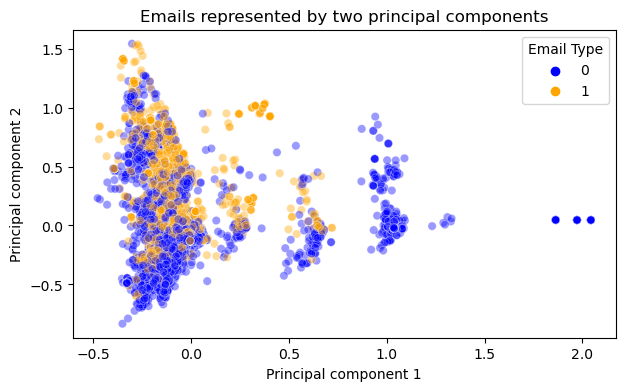

In [11]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
components = pca.fit_transform(X)

plt.figure(figsize=(7, 4))
sns.scatterplot(
    x=components[:, 0],
    y=components[:, 1],
    hue=y,
    palette={0: "blue", 1: "orange"}, #blue is non scam orange is scam
    alpha=0.4
)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("Emails represented by two principal components")
plt.show()

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

---
The training and test $R^2$ values are printed below. In Phase 1, training $R^2$ was 0.7662 and test $R^2$ was 0.6683. The training performance was nearly identical to the original regression, but the test performance improved by a lot.

This comparison uses the same train-test split, and PCA is fitted only on the training data before transforming the test data. That makes the comparison valid. However, the original regression was numerically unstable, so this result alone does not show that PCA is better than a numerically stable regression on the original features. I kept the required linear regression and 2,610 components.


In [12]:
pca_reg = PCA(n_components=2610)

X_train_pca = pca_reg.fit_transform(X_train)
X_test_pca = pca_reg.transform(X_test)

pca_fit = LinearRegression().fit(X_train_pca, y_train)

R2_train = pca_fit.score(X_train_pca, y_train)
R2_test = pca_fit.score(X_test_pca, y_test)

print("R squared for training data:", R2_train)
print("R squared for testing data:", R2_test)

R squared for training data: 0.7662326827745852
R squared for testing data: 0.6683390643101161


In [13]:
print("Retained explained-variance fraction:",
      pca_reg.explained_variance_ratio_.sum())
print("Smallest retained singular values:", pca_reg.singular_values_[-5:])
print("Retained singular-value ratio:",
      pca_reg.singular_values_[0] / pca_reg.singular_values_[-1])


Retained explained-variance fraction: 0.9998620409568273
Smallest retained singular values: [1.15335116 1.1496957  1.13568019 1.1319785  1.09365497]
Retained singular-value ratio: 34.07850612695235


**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---
PCA combines overlapping information from many features into components. Keeping fewer components can remove redundant or unstable directions, which can make the regression predictions more reliable on unseen data. However, it does not guarantee better predictions, since the directions removed might contain useful information about the outcome. PCA keeps directions with more feature variance, not necessarily the ones that best separate scam emails. The components can also be harder to interpret than the original words.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements of the AI were fixing my Q2, Q4, and Q5. Q2 now explains the evidence of numerical instability, Q4 preserves the valid comparision and qualifies its conclusion, and Q5 explains PCA's tradeoffs. Some mistakes that were made were just some overstatements. GPT seemed very confident, espcially around Q4 when it called it a "necessary correction" when I feel the code was already correct. This made me spend a bit more time trying to figure out what it meant, and when I would ask for clarification it seemed to correct its own mistake. Another thing is that it would occasionally produce incorrect code, which was not caught until I reran the notebook. Also, it seems to overcomplicate things at times. Of course it's good to play it extra safe and have lots of double checks and tests, but sometimes it gets too much to the point where the original code and meaning can be lost. I verified it by making sure all the code ran successfully and ensuring Q2 and Q4 produced the same original correct results. One concern I had was mainly how the R squared value was such a big negative number, and im still uncertain about why the predictions became so extreme.